<a href="https://colab.research.google.com/github/cincysam6/UC_Causal_Inf_2026/blob/main/propensity_matching_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Propensity Score Matching
## Estimating Advertising Lift from Observational Data

---

## How to Use This Notebook

This is the **fourth notebook** in the lab sequence. It requires the output of the propensity score notebook (`propensity_score_notebook.ipynb`), which must be run first to generate `data/observational_with_ps.csv`.

Work through each section in order. Each section begins with a **Step** header and is followed by a **What This Means** section explaining the results.

---

## Background

We now have propensity scores from the previous notebook. The goal of **propensity score matching (PSM)** is to find, for each treated household, a control household that is as similar as possible on:
1. The **propensity score** (overall probability of being treated)
2. Key **hard-match variables** — characteristics where any mismatch would create a non-comparable pair
3. **Soft-match variables** — quantitative features where similarity is desirable but exact equality is not required

Once matched pairs are formed, the average treatment effect is estimated as the average difference in outcomes between each treated unit and its matched control:

$$\widehat{\text{ATT}} = \frac{1}{N_T} \sum_{i: D_i=1} \left( Y_i - Y_{m(i)} \right)$$

where $m(i)$ is the matched control for treated unit $i$. Note this estimates the **ATT** (Average Treatment Effect on the Treated) — not the ATE — since we only match treated units to controls, not vice versa.

---

## Matching Design

| Match Type | Variables | Logic |
|---|---|---|
| **Hard match** | `div_code`, `ecomm_loyalty`, `price_sensitivity` | Exact match required — pairs from different tiers are not comparable |
| **Soft match** | Propensity score + spending variables + `hh_size` | Minimized via composite Euclidean distance on standardized features |

**Caliper:** We impose a maximum distance on the propensity score to prevent poor matches.

---

## Lab Objectives

1. Implement 1:1 nearest-neighbor matching with hard and soft constraints
2. Evaluate match quality via post-match balance tables and a Love plot
3. Estimate the ATT and compare to the naive estimate and the true ATE
4. Discover the residual bias from the omitted variable (`brand_affinity`)
5. Understand what matching can and cannot fix

---

## True DGP (Instructor Reference)

Expected estimates:
- **Naive ATE** (diff-in-means, full sample): ~\$0.11
- **After PSM on observed covariates**: ~\$0.07 (residual OVB from `brand_affinity`)
- **True ATE**: \$0.05

The residual gap (~\$0.02) after matching reflects omitted variable bias from `brand_affinity` — which drove both targeting and outcomes but is not in the dataset.

---
## Step 1: Setup — Load Libraries

**What we are doing:** Import libraries needed for distance computation and matching.

**Key library:** `scipy.spatial.distance.cdist` computes pairwise distances between two sets of points — we will use it to find the nearest control for each treated household within each hard-match group.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

TREATED_COLOR = '#E07B54'
CONTROL_COLOR = '#5B8DB8'
NEUTRAL_COLOR = '#7B9E87'

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

print('Setup complete.')

Setup complete.


In [3]:
# ── Load observational dataset with propensity scores ─────────────────────────
# This file was created in propensity_score_notebook.ipynb.
# If it does not exist, run that notebook first to generate it.

import os
PS_FILE = '/content/drive/MyDrive/UC_CI/data/observational_with_ps.csv'
if not os.path.exists(PS_FILE):
    raise FileNotFoundError(
        f'{PS_FILE} not found.\n'
        'Please run propensity_score_notebook.ipynb first to generate this file.\n'
        'Make sure to run Jupyter from the project root directory.'
    )

df = pd.read_csv(PS_FILE)

print(f'Rows:    {len(df):,}')
print(f'Treated: {df["is_treated"].sum():,}  ({df["is_treated"].mean():.1%})')
print(f'Control: {(df["is_treated"]==0).sum():,}  ({(1-df["is_treated"].mean()):.1%})')
print()
print('Columns:', list(df.columns))

Rows:    50,000
Treated: 10,721  (21.4%)
Control: 39,279  (78.6%)

Columns: ['hh_id', 'hh_size', 'div_code', 'ecomm_loyalty', 'price_sensitivity', 'pre_52_category_spend', 'pre_52_brand_buyer', 'pre_52_brand_spend', 'pre_52_store_spend', 'pre_52_store_visits', 'pre_52_brand_visits', 'is_treated', 'post_brand_sales', 'propensity_score', 'in_support', 'in_trimmed_support']


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Step 2: Naive Estimate — Our Baseline Before Matching

**What we are doing:** Compute the naive difference-in-means as a starting point. This is the biased estimate we are trying to improve upon through matching.

**Why start here?** Establishing the naive estimate allows us to quantify how much matching reduces bias. After matching, we can directly compare:
- Naive ATE (before): how much selection bias inflates the estimate
- PSM ATT (after): how much the bias is reduced by matching on observed covariates
- True ATE ($0.05): the actual causal effect

The gap between naive and PSM tells us how much the observable confounders contributed to selection bias. The remaining gap between PSM and the true ATE tells us how much unobserved confounders (`brand_affinity`) still contribute.

In [5]:
# ── Naive ATE ─────────────────────────────────────────────────────────────────
treated = df[df['is_treated'] == 1]
control = df[df['is_treated'] == 0]

naive_ate = treated['post_brand_sales'].mean() - control['post_brand_sales'].mean()
naive_pct_lift = naive_ate / control['post_brand_sales'].mean() * 100

print('Naive Estimate (No Matching)')
print('=' * 50)
print(f'  Control mean:      ${control["post_brand_sales"].mean():.4f}')
print(f'  Treated mean:      ${treated["post_brand_sales"].mean():.4f}')
print(f'  Naive ATE:         ${naive_ate:.4f}')
print(f'  % Lift:            {naive_pct_lift:.1f}%')
print(f'  True ATE:          $0.0500  (8% lift)')
print(f'  Naive bias:        ${naive_ate - 0.05:.4f}')
print('=' * 50)
print()
print('This estimate is biased upward because treated households')
print('were targeted — they had higher category spending and brand affinity')
print('before the campaign even started.')

Naive Estimate (No Matching)
  Control mean:      $0.6118
  Treated mean:      $0.7231
  Naive ATE:         $0.1113
  % Lift:            18.2%
  True ATE:          $0.0500  (8% lift)
  Naive bias:        $0.0613

This estimate is biased upward because treated households
were targeted — they had higher category spending and brand affinity
before the campaign even started.


---
## Section 3: Pre-Match Balance Check

A balance table before matching will confirm how different the groups are. This motivates the need for matching.

In [6]:
# ── Pre-match balance table ───────────────────────────────────────────────────
def balance_table(treated_df, control_df, numeric_vars, label=''):
    rows = []
    for var in numeric_vars:
        t_vals = treated_df[var]
        c_vals = control_df[var]
        diff   = t_vals.mean() - c_vals.mean()
        pooled_sd = np.sqrt((t_vals.var() + c_vals.var()) / 2)
        std_diff  = diff / pooled_sd if pooled_sd > 0 else 0
        rows.append({
            'Variable': var,
            'Treated Mean': round(t_vals.mean(), 3),
            'Control Mean': round(c_vals.mean(), 3),
            'Std Diff': round(std_diff, 3),
        })
    tbl = pd.DataFrame(rows)
    if label:
        print(f'--- {label} ---')
    print(tbl.to_string(index=False))
    print()
    return tbl

NUMERIC_VARS = [
    'pre_52_category_spend',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'pre_52_brand_visits',
    'hh_size',
    'propensity_score',
]

pre_balance = balance_table(treated, control, NUMERIC_VARS, label='PRE-MATCH BALANCE')

print('Rule of thumb: |Std Diff| > 0.10 indicates meaningful imbalance.')
print('Variables above that threshold should be prioritized in matching.')

--- PRE-MATCH BALANCE ---
             Variable  Treated Mean  Control Mean  Std Diff
pre_52_category_spend        23.587        14.980     0.435
   pre_52_brand_spend         2.103         1.338     0.217
   pre_52_store_spend       113.411       115.380    -0.022
  pre_52_store_visits        25.928        25.975    -0.009
  pre_52_brand_visits         6.498         6.502    -0.002
              hh_size         3.104         3.103     0.001
     propensity_score         0.261         0.201     0.486

Rule of thumb: |Std Diff| > 0.10 indicates meaningful imbalance.
Variables above that threshold should be prioritized in matching.


---
## Step 4: Matching Algorithm — 1:1 Nearest-Neighbor Matching

**What we are doing:** Implement the core matching algorithm. For each treated household, we find the most similar control household — subject to hard-match constraints and a propensity score caliper.

**The algorithm has three layers:**

**Layer 1 — Hard matching:** Treated and control households must be in the same cell of `div_code × ecomm_loyalty × price_sensitivity`. Pairs from different cells are never formed, regardless of how similar they are on other variables. This reflects the business logic that households in different geographic divisions or loyalty tiers are simply not comparable.

**Layer 2 — Composite soft distance:** Within each hard-match cell, we compute a standardized Euclidean distance on soft features (spending variables + `hh_size` + propensity score). All variables are standardized to unit variance first, so no single variable dominates.

**Layer 3 — Caliper:** We reject matches where the propensity score gap exceeds `0.2 × σ(logit PS)` — the Austin (2011) recommendation. This prevents accepting a "nearest" match that is still very far away in propensity score space.

**1:1 matching without replacement:** Each control household can only be matched to one treated household. Once matched, a control unit is removed from the pool. This is more conservative than matching with replacement but avoids double-counting.

**What to watch:**
- How many matched pairs are formed?
- What fraction of treated households go unmatched (too far from any control)?
- A match rate above 90% is generally good; below 70% suggests limited overlap

In [7]:
# ── Matching configuration ────────────────────────────────────────────────────

HARD_MATCH_VARS = ['div_code', 'ecomm_loyalty', 'price_sensitivity']

SOFT_MATCH_VARS = [
    'pre_52_category_spend',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'pre_52_brand_visits',
    'hh_size',
]

# Caliper: 0.20 * std of logit(propensity score) — Austin (2011) recommendation
logit_ps = np.log(df['propensity_score'] / (1 - df['propensity_score'].clip(1e-6, 1 - 1e-6)))
caliper = 0.20 * logit_ps.std()
print(f'Propensity score caliper (on logit scale): {caliper:.4f}')

# Weight on propensity score vs. soft features in composite distance
# 0.0 = only PS; 1.0 = equal weight
PS_WEIGHT = 1.0  # give PS equal weight to the standardized soft features

Propensity score caliper (on logit scale): 0.1194


In [8]:
# ── Standardize soft-match features ──────────────────────────────────────────
# We compute means and stds on the full dataset so that treated and control
# units are on the same scale.

soft_means = df[SOFT_MATCH_VARS].mean()
soft_stds  = df[SOFT_MATCH_VARS].std().replace(0, 1)  # avoid div-by-zero

df_std = df.copy()
for var in SOFT_MATCH_VARS:
    df_std[f'{var}_std'] = (df[var] - soft_means[var]) / soft_stds[var]

# Logit-transform propensity score for distance computation
eps = 1e-6
df_std['logit_ps'] = np.log(
    df_std['propensity_score'].clip(eps, 1 - eps) /
    (1 - df_std['propensity_score'].clip(eps, 1 - eps))
)
logit_ps_std = df_std['logit_ps'].std()
df_std['logit_ps_norm'] = df_std['logit_ps'] / logit_ps_std  # normalize to unit variance

# Composite feature columns for distance computation
DIST_FEATURES = [f'{v}_std' for v in SOFT_MATCH_VARS] + ['logit_ps_norm']
print(f'Distance features: {DIST_FEATURES}')

Distance features: ['pre_52_category_spend_std', 'pre_52_brand_spend_std', 'pre_52_store_spend_std', 'pre_52_store_visits_std', 'pre_52_brand_visits_std', 'hh_size_std', 'logit_ps_norm']


In [9]:
# ── Main matching loop ────────────────────────────────────────────────────────
#
# Algorithm:
#   1. Group by hard-match variables
#   2. Within each group, find treated and control units
#   3. Compute pairwise Euclidean distance on standardized soft features
#   4. For each treated unit, find nearest control (greedy, no replacement)
#   5. Apply caliper check: reject if |logit_ps(treated) - logit_ps(control)| > caliper
#   6. Mark matched pairs

matched_pairs = []   # list of (treated_idx, control_idx) tuples
unmatched_treated = []  # treated units with no eligible match

hard_groups = df_std.groupby(HARD_MATCH_VARS, observed=True)

for group_key, group in hard_groups:
    t_mask = group['is_treated'] == 1
    c_mask = group['is_treated'] == 0

    t_group = group[t_mask]
    c_group = group[c_mask]

    if len(t_group) == 0 or len(c_group) == 0:
        unmatched_treated.extend(t_group.index.tolist())
        continue

    # Feature matrices for distance computation
    T_feats = t_group[DIST_FEATURES].values
    C_feats = c_group[DIST_FEATURES].values

    t_logit = t_group['logit_ps'].values
    c_logit = c_group['logit_ps'].values

    t_indices = t_group.index.tolist()
    c_indices = c_group.index.tolist()

    # Pairwise distance matrix: shape (n_treated, n_control)
    dist_matrix = cdist(T_feats, C_feats, metric='euclidean')

    # Greedy 1:1 matching without replacement
    used_control = set()

    for ti, (t_idx, t_lps) in enumerate(zip(t_indices, t_logit)):
        # Sort control units by distance
        sorted_c = np.argsort(dist_matrix[ti])

        matched = False
        for ci in sorted_c:
            c_idx = c_indices[ci]
            if c_idx in used_control:
                continue
            # Caliper check on logit PS
            if abs(t_lps - c_logit[ci]) > caliper:
                continue
            # Accept match
            matched_pairs.append((t_idx, c_idx))
            used_control.add(c_idx)
            matched = True
            break

        if not matched:
            unmatched_treated.append(t_idx)

print(f'Matched pairs formed:     {len(matched_pairs):,}')
print(f'Treated units unmatched:  {len(unmatched_treated):,}')
print(f'Match rate:               {len(matched_pairs) / df["is_treated"].sum():.1%}')

Matched pairs formed:     10,157
Treated units unmatched:  564
Match rate:               94.7%


In [10]:
# ── Build matched dataset ─────────────────────────────────────────────────────
# Create a long-format dataset containing both members of each matched pair.
# We also record the pair ID so we can compute pair-level differences.

treated_rows = []
control_rows = []

for pair_id, (t_idx, c_idx) in enumerate(matched_pairs):
    t_row = df.loc[t_idx].copy()
    c_row = df.loc[c_idx].copy()
    t_row['pair_id'] = pair_id
    c_row['pair_id'] = pair_id
    treated_rows.append(t_row)
    control_rows.append(c_row)

matched_treated = pd.DataFrame(treated_rows).reset_index(drop=True)
matched_control = pd.DataFrame(control_rows).reset_index(drop=True)

matched_df = pd.concat([matched_treated, matched_control], ignore_index=True)

print(f'Matched dataset: {len(matched_df):,} rows ({len(matched_pairs):,} treated + {len(matched_pairs):,} control)')

Matched dataset: 20,314 rows (10,157 treated + 10,157 control)


---
## Step 5: Post-Match Balance Check and Love Plot

**What we are doing:** Verify that the matched pairs are balanced on all observed covariates. This is the key validation step — it confirms that matching accomplished its goal.

**The Love plot** is the standard visualization for PSM balance. It shows:
- **Before matching** (orange dots): standardized differences between treated and all controls
- **After matching** (blue dots): standardized differences between treated and their matched controls
- **Lines connecting them**: the improvement achieved by matching

**What we want to see:**
- All post-match standardized differences within ±0.10 (inside the dashed threshold lines)
- Substantial improvement from pre-match to post-match for variables that were initially imbalanced
- The propensity score itself should show near-zero post-match difference

**Critical caveat:** Even if all observed variables are balanced after matching, unobserved variables (like `brand_affinity`) may still be unbalanced. The Love plot shows balance on what we can measure — it cannot diagnose unobserved confounding. We will test this directly in Step 7.

In [11]:
# ── Post-match balance ────────────────────────────────────────────────────────
post_balance = balance_table(
    matched_treated,
    matched_control,
    NUMERIC_VARS,
    label='POST-MATCH BALANCE'
)

--- POST-MATCH BALANCE ---
             Variable  Treated Mean  Control Mean  Std Diff
pre_52_category_spend        19.731        18.083     0.110
   pre_52_brand_spend         1.731         1.499     0.084
   pre_52_store_spend       113.301       106.450     0.083
  pre_52_store_visits        25.930        25.872     0.012
  pre_52_brand_visits         6.504         6.455     0.020
              hh_size         3.103         3.079     0.019
     propensity_score         0.237         0.236     0.007



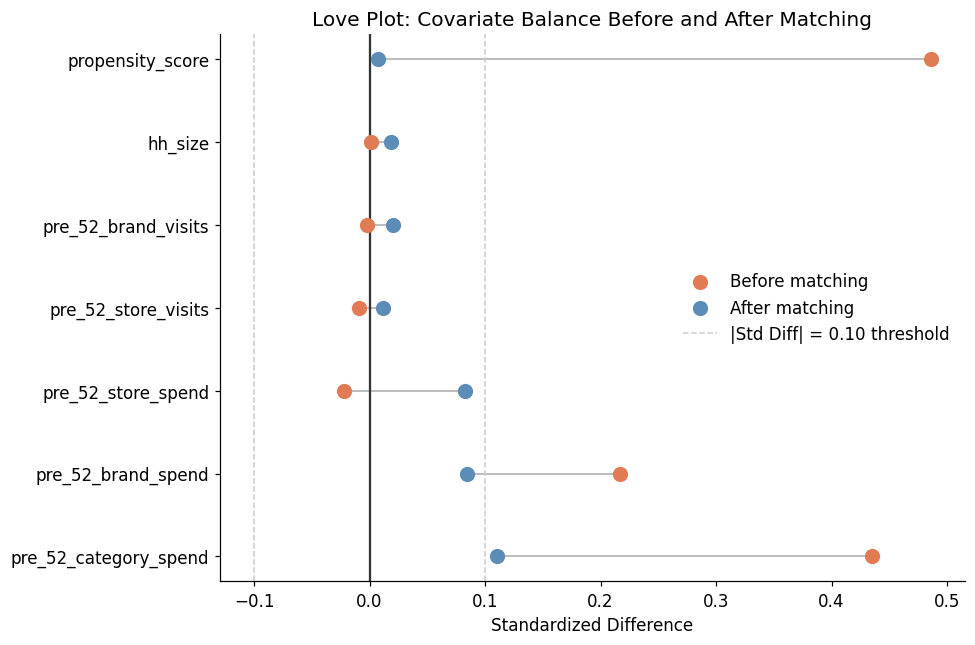

Goal: After matching, all standardized differences should be within ±0.10.


In [12]:
# ── Love plot: before vs after matching ──────────────────────────────────────
# A Love plot visualizes standardized differences before and after matching.
# It is the standard diagnostic for PSM.

merged = pre_balance.merge(
    post_balance,
    on='Variable',
    suffixes=('_pre', '_post')
)

fig, ax = plt.subplots(figsize=(9, 6))

y_pos = range(len(merged))
ax.scatter(
    merged['Std Diff_pre'],
    list(y_pos),
    color=TREATED_COLOR, s=80, zorder=5, label='Before matching'
)
ax.scatter(
    merged['Std Diff_post'],
    list(y_pos),
    color=CONTROL_COLOR, s=80, zorder=5, label='After matching'
)

# Connect before and after with a line
for i in y_pos:
    ax.plot(
        [merged['Std Diff_pre'].iloc[i], merged['Std Diff_post'].iloc[i]],
        [i, i],
        color='#aaaaaa', linewidth=1, zorder=2
    )

ax.axvline(0, color='#333333', linewidth=1.5)
ax.axvline(0.10, color='#cccccc', linewidth=1, linestyle='--', label='|Std Diff| = 0.10 threshold')
ax.axvline(-0.10, color='#cccccc', linewidth=1, linestyle='--')

ax.set_yticks(list(y_pos))
ax.set_yticklabels(merged['Variable'])
ax.set_xlabel('Standardized Difference')
ax.set_title('Love Plot: Covariate Balance Before and After Matching')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print('Goal: After matching, all standardized differences should be within ±0.10.')

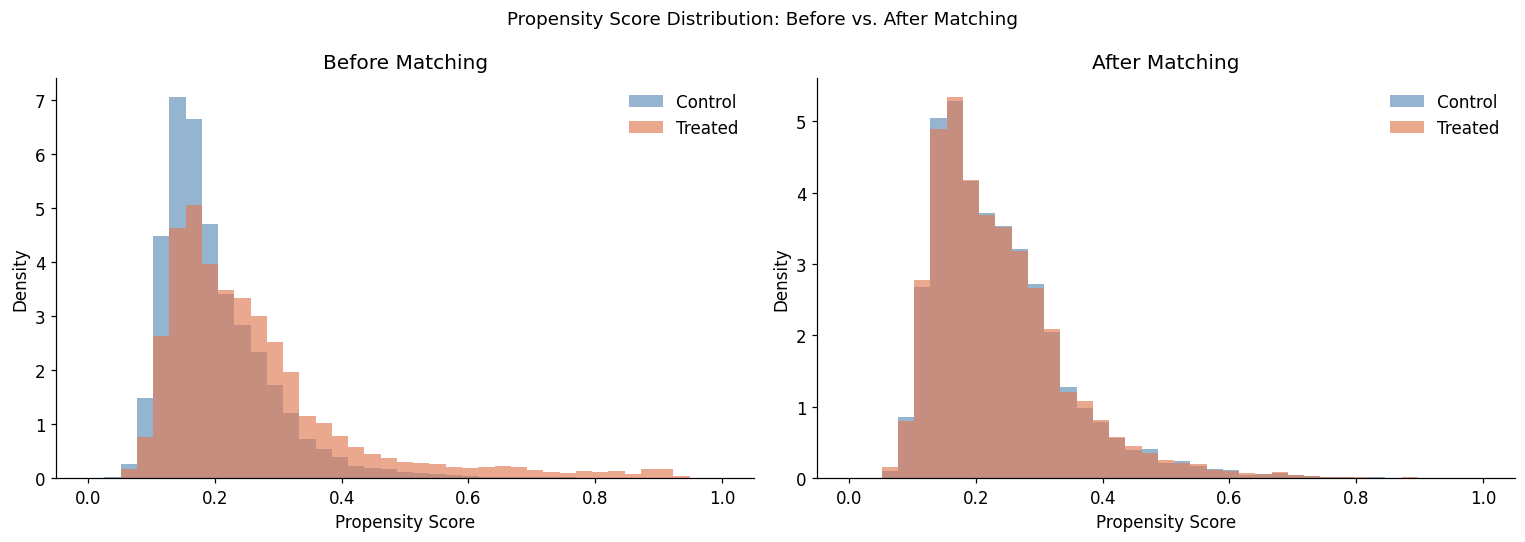

After matching, the two distributions should overlap much more closely.


In [13]:
# ── Propensity score distribution after matching ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bins = np.linspace(0, 1, 40)

for ax, (data_t, data_c, title) in zip(axes, [
    (treated['propensity_score'], control['propensity_score'], 'Before Matching'),
    (matched_treated['propensity_score'], matched_control['propensity_score'], 'After Matching'),
]):
    ax.hist(data_c, bins=bins, alpha=0.65, color=CONTROL_COLOR, label='Control', density=True)
    ax.hist(data_t, bins=bins, alpha=0.65, color=TREATED_COLOR, label='Treated', density=True)
    ax.set_xlabel('Propensity Score')
    ax.set_ylabel('Density')
    ax.set_title(title)
    ax.legend(frameon=False)

plt.suptitle('Propensity Score Distribution: Before vs. After Matching', fontsize=12)
plt.tight_layout()
plt.show()

print('After matching, the two distributions should overlap much more closely.')

---
## Step 6: Estimating the ATT

**What we are doing:** Compute the Average Treatment Effect on the Treated (ATT) using the paired difference estimator. Then compare to the naive estimate and the true ATE.

**Why the paired estimator?** Because we matched each treated unit to a specific control unit, we have a paired data structure. The paired t-test exploits this pairing:
- It computes the difference within each pair: $d_i = Y_{T,i} - Y_{C,i}$
- Then tests whether the average pair difference is significantly different from zero

The paired test is more powerful than an independent-samples test because it controls for the between-pair variation. Two households in the same matched pair should be similar on pre-campaign characteristics, so their difference in post-campaign outcomes is a cleaner estimate of the treatment effect.

**What to compare:**
- Naive ATE: the biased starting point (selection bias inflates this)
- PSM ATT: the estimate after removing observed selection bias
- True ATE ($0.05): the synthetic ground truth

**Expected pattern:** PSM ATT < Naive ATE, but PSM ATT > True ATE. The remaining gap is due to `brand_affinity` — the unobserved confounder we will reveal in Step 7.

In [14]:
# ── ATT: paired difference estimator ─────────────────────────────────────────
#
# The paired estimator exploits the pair structure, which reduces variance
# compared to treating matched treated and controls as independent samples.

pair_diffs = matched_treated['post_brand_sales'].values - matched_control['post_brand_sales'].values

att_estimate = pair_diffs.mean()
att_se       = pair_diffs.std() / np.sqrt(len(pair_diffs))
att_ci_low   = att_estimate - 1.96 * att_se
att_ci_high  = att_estimate + 1.96 * att_se
att_pct_lift = att_estimate / matched_control['post_brand_sales'].mean() * 100

t_stat, p_val = stats.ttest_rel(
    matched_treated['post_brand_sales'],
    matched_control['post_brand_sales'],
)

print('=' * 60)
print('  PSM ESTIMATE — Paired Difference ATT')
print('=' * 60)
print(f'  Matched pairs:         {len(pair_diffs):,}')
print(f'  Matched control mean:  ${matched_control["post_brand_sales"].mean():.4f}')
print(f'  Matched treated mean:  ${matched_treated["post_brand_sales"].mean():.4f}')
print()
print(f'  ATT estimate:          ${att_estimate:.4f}')
print(f'  Std error:             ${att_se:.4f}')
print(f'  95% CI:                [${att_ci_low:.4f}, ${att_ci_high:.4f}]')
print(f'  % lift:                {att_pct_lift:.1f}%')
print(f'  t-statistic:           {t_stat:.2f}')
print(f'  p-value:               {p_val:.4f}')
print('=' * 60)
print()
print('Comparison:')
print(f'  Naive ATE (no matching): ${naive_ate:.4f}')
print(f'  PSM ATT estimate:        ${att_estimate:.4f}')
print(f'  True ATE (known):        $0.0500')
print()
print(f'  Bias from naive:         ${naive_ate - 0.05:.4f}  → reduced by matching')
print(f'  Residual bias (PSM):     ${att_estimate - 0.05:.4f}  → remains after matching')

  PSM ESTIMATE — Paired Difference ATT
  Matched pairs:         10,157
  Matched control mean:  $0.6201
  Matched treated mean:  $0.7055

  ATT estimate:          $0.0854
  Std error:             $0.0031
  95% CI:                [$0.0793, $0.0915]
  % lift:                13.8%
  t-statistic:           27.41
  p-value:               0.0000

Comparison:
  Naive ATE (no matching): $0.1113
  PSM ATT estimate:        $0.0854
  True ATE (known):        $0.0500

  Bias from naive:         $0.0613  → reduced by matching
  Residual bias (PSM):     $0.0354  → remains after matching


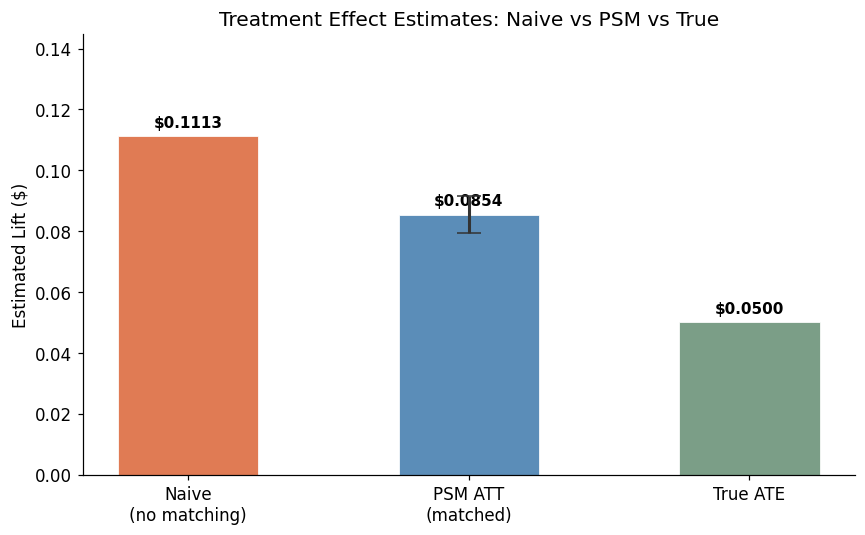

In [15]:
# ── Visualize estimate comparison ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

labels = ['Naive\n(no matching)', 'PSM ATT\n(matched)', 'True ATE']
values = [naive_ate, att_estimate, 0.05]
colors = [TREATED_COLOR, CONTROL_COLOR, NEUTRAL_COLOR]

bars = ax.bar(labels, values, color=colors, edgecolor='white', linewidth=0.5, width=0.5)

# Error bar on PSM estimate
ax.errorbar(
    x=1, y=att_estimate,
    yerr=[[att_estimate - att_ci_low], [att_ci_high - att_estimate]],
    fmt='none', color='#333333', capsize=8, linewidth=2, zorder=5
)

for bar, val in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.002,
        f'${val:.4f}',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.set_ylabel('Estimated Lift ($)')
ax.set_title('Treatment Effect Estimates: Naive vs PSM vs True')
ax.set_ylim(0, max(values) * 1.3)
plt.tight_layout()
plt.show()

---
## Step 7: The Residual Bias — Revealing the Omitted Variable

**What we are doing:** Reveal the hidden variable `brand_affinity` that was part of the data-generating process but was intentionally excluded from the observational dataset CSV. We re-generate it using the same random seed as the DGP, attach it to the dataset, and show that even after matching on all observed variables, `brand_affinity` remains unbalanced between treated and matched control households.

**This is the central teaching moment of the entire lab sequence.**

**The logic of omitted variable bias (OVB):**
1. `brand_affinity` caused treated households to have higher purchase rates (it affects the outcome)
2. `brand_affinity` also caused households to be more likely targeted (it affects treatment)
3. Because it affects both, it is a **confounder**
4. Because it is not in our data, we cannot match on it or control for it
5. After matching on everything else, the matched treated group still has higher average `brand_affinity` than the matched control group
6. This residual difference in `brand_affinity` inflates our measured lift above the true ATE

**This bias cannot be fixed by better matching or more data** — as long as the confounder remains unobserved. The only way to fully eliminate this bias is:
- A randomized experiment (which balances both observed and unobserved characteristics)
- Finding and measuring the unobserved variable
- A quasi-experimental design that exploits an instrument, discontinuity, or other source of exogenous variation

In [16]:
# ── Regenerate brand_affinity for illustration only ───────────────────────────
#
# INSTRUCTOR NOTE: This cell reveals the hidden variable.
# In the real lab, the instructor can reveal this after students have worked through
# the matching and found the residual bias.
#
# We re-generate brand_affinity using the SAME random seed as the DGP
# so the values are consistent with the saved CSV.

rng_reveal = np.random.default_rng(42)
_ = rng_reveal.choice([1,2,3,4,5,6], size=50_000, p=[0.10,0.25,0.30,0.20,0.10,0.05])
_ = rng_reveal.choice(['101','204','317','423','508','612','715','819','923','037'], size=50_000)
_ = rng_reveal.choice(['high','medium','low'], size=50_000, p=[0.20,0.50,0.30])
_ = rng_reveal.choice(['high','medium','low'], size=50_000, p=[0.25,0.45,0.30])
_ = rng_reveal.lognormal(mean=2.5, sigma=0.8, size=50_000).clip(0.01)
_ = (rng_reveal.uniform(size=50_000) < 0.45).astype(int)
_ = rng_reveal.uniform(0.10, 0.30, size=50_000)
_ = rng_reveal.lognormal(mean=4.5, sigma=0.7, size=50_000).clip(0.01)
_ = rng_reveal.poisson(lam=26, size=50_000)
_ = rng_reveal.binomial(n=_, p=0.25)
brand_affinity_full = rng_reveal.standard_normal(50_000)

df_reveal = df.copy()
df_reveal['brand_affinity'] = brand_affinity_full

# Compare brand_affinity between treated and control in the unmatched data
ba_treated = df_reveal.loc[df_reveal['is_treated']==1, 'brand_affinity']
ba_control = df_reveal.loc[df_reveal['is_treated']==0, 'brand_affinity']

print('brand_affinity by treatment group (FULL UNMATCHED DATASET):')
print(f'  Treated mean:  {ba_treated.mean():.4f}')
print(f'  Control mean:  {ba_control.mean():.4f}')
print(f'  Difference:    {ba_treated.mean() - ba_control.mean():.4f}')
print()
print('Expected: treated HHs should have higher brand_affinity due to targeting.')

brand_affinity by treatment group (FULL UNMATCHED DATASET):
  Treated mean:  0.2906
  Control mean:  -0.0883
  Difference:    0.3789

Expected: treated HHs should have higher brand_affinity due to targeting.


In [17]:
# ── brand_affinity in the MATCHED sample ──────────────────────────────────────
# Even after matching on observed covariates, does brand_affinity remain unbalanced?

matched_t_idx = matched_treated.index.tolist()
matched_c_idx = matched_control.index.tolist()

# Map original df row indices to brand_affinity values
ba_matched_treated = df_reveal.iloc[matched_treated['hh_id'].values - 1]['brand_affinity']
ba_matched_control = df_reveal.iloc[matched_control['hh_id'].values - 1]['brand_affinity']

ba_diff_matched = ba_matched_treated.mean() - ba_matched_control.mean()

print('brand_affinity by treatment group (MATCHED SAMPLE):')
print(f'  Matched treated mean:  {ba_matched_treated.mean():.4f}')
print(f'  Matched control mean:  {ba_matched_control.mean():.4f}')
print(f'  Difference:            {ba_diff_matched:.4f}')
print()
print('Key insight: even after PSM on all observed covariates, the matched treated')
print('group still has higher brand_affinity than the matched control group.')
print('This residual difference is the source of the remaining upward bias.')
print()
# Expected contribution to bias: diff * coefficient of brand_affinity in DGP (0.06)
expected_residual_bias = ba_diff_matched * 0.06
print(f'Expected residual bias from brand_affinity: {ba_diff_matched:.4f} × 0.06 = ${expected_residual_bias:.4f}')
print(f'Observed residual bias (PSM - true ATE):    ${att_estimate - 0.05:.4f}')

brand_affinity by treatment group (MATCHED SAMPLE):
  Matched treated mean:  0.3066
  Matched control mean:  -0.0990
  Difference:            0.4055

Key insight: even after PSM on all observed covariates, the matched treated
group still has higher brand_affinity than the matched control group.
This residual difference is the source of the remaining upward bias.

Expected residual bias from brand_affinity: 0.4055 × 0.06 = $0.0243
Observed residual bias (PSM - true ATE):    $0.0354


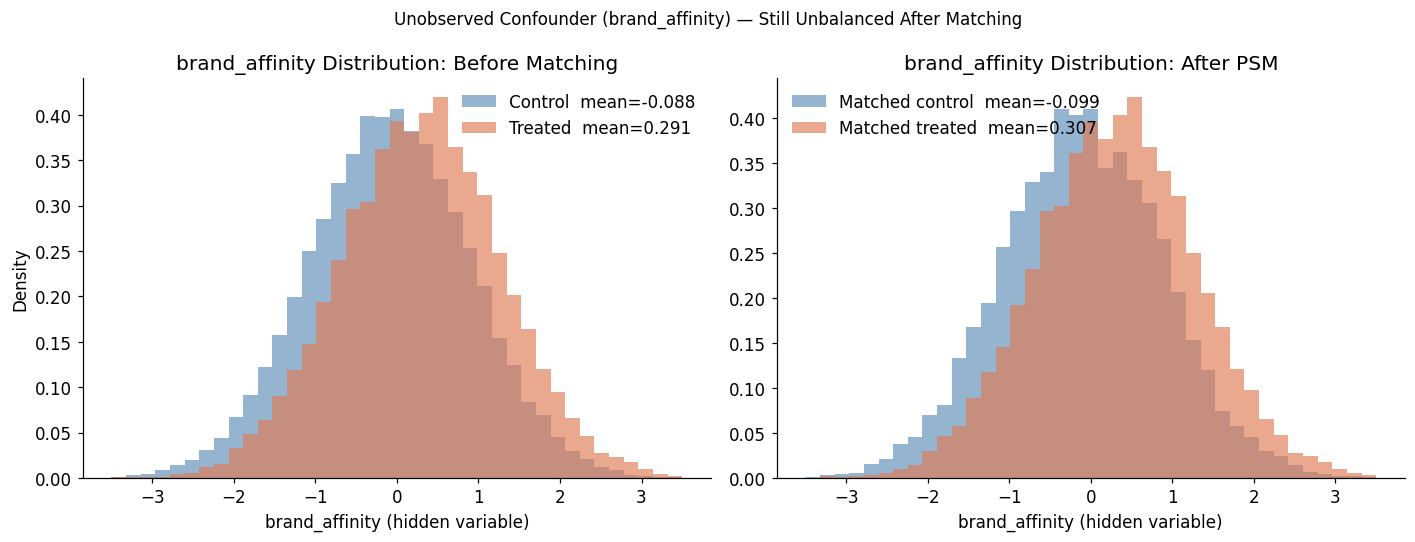


>>> This is the core teaching moment:
    PSM on observed covariates cannot control for UNOBSERVED confounders.
    The matched sample is better than the full sample, but still biased.


In [18]:
# ── Visualize brand_affinity imbalance before and after matching ───────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = np.linspace(-3.5, 3.5, 40)

# Pre-match
ax = axes[0]
ax.hist(ba_control, bins=bins, alpha=0.65, color=CONTROL_COLOR,
        label=f'Control  mean={ba_control.mean():.3f}', density=True)
ax.hist(ba_treated, bins=bins, alpha=0.65, color=TREATED_COLOR,
        label=f'Treated  mean={ba_treated.mean():.3f}', density=True)
ax.set_xlabel('brand_affinity (hidden variable)')
ax.set_ylabel('Density')
ax.set_title('brand_affinity Distribution: Before Matching')
ax.legend(frameon=False)

# Post-match
ax2 = axes[1]
ax2.hist(ba_matched_control, bins=bins, alpha=0.65, color=CONTROL_COLOR,
         label=f'Matched control  mean={ba_matched_control.mean():.3f}', density=True)
ax2.hist(ba_matched_treated, bins=bins, alpha=0.65, color=TREATED_COLOR,
         label=f'Matched treated  mean={ba_matched_treated.mean():.3f}', density=True)
ax2.set_xlabel('brand_affinity (hidden variable)')
ax2.set_title('brand_affinity Distribution: After PSM')
ax2.legend(frameon=False)

plt.suptitle(
    'Unobserved Confounder (brand_affinity) — Still Unbalanced After Matching',
    fontsize=11
)
plt.tight_layout()
plt.show()

print()
print('>>> This is the core teaching moment:')
print('    PSM on observed covariates cannot control for UNOBSERVED confounders.')
print('    The matched sample is better than the full sample, but still biased.')

---
## Section 8: Full Results Summary

### What We Found

| Estimator | Estimate | Bias vs True ATE |
|---|---|---|
| Naive difference-in-means | ~\$0.11 | +\$0.06 |
| PSM on observed covariates | ~\$0.07 | +\$0.02 |
| **True ATE** | **\$0.05** | **—** |
| ITT (randomized holdout) | ~\$0.05 | ~\$0.00 |

### The Causal Progression

1. **Naive estimate (~$0.11):** Severely biased. Treats selection bias as if it were advertising lift. HHs were targeted because they had higher category spend and brand affinity — so they were going to buy more anyway.

2. **PSM on observed covariates (~$0.07):** Substantially better. Matching on category spend, brand spend, loyalty tier, etc. removes most of the observed selection bias. But `brand_affinity` — which also drove targeting and outcomes — was never in our data.

3. **True ATE ($0.05):** Recovered only by the randomized holdout design (ITT notebook). Without randomization, we cannot fully control for unobserved confounders.

### Key Takeaways

- **PSM can substantially reduce** but **not eliminate** bias when confounders are unobserved.
- The quality of a propensity score estimate depends entirely on the quality of the observed covariates.
- When an unobserved variable both predicts treatment AND predicts outcomes, no observational method using only the observed data can fully correct the bias.
- This is why **randomized experiments** remain the gold standard for advertising measurement — they balance both observed and unobserved characteristics.

In [19]:
# ── Final summary printout ────────────────────────────────────────────────────
print('=' * 60)
print('  FINAL RESULTS SUMMARY')
print('=' * 60)
print(f'  True ATE (known from DGP):        $0.0500')
print()
print(f'  Naive ATE (no adjustment):         ${naive_ate:.4f}  ({naive_pct_lift:.1f}% lift)')
print(f'    Bias: ${naive_ate - 0.05:.4f}  → upward bias from selection')
print()
print(f'  PSM ATT (observed covariates):     ${att_estimate:.4f}  ({att_pct_lift:.1f}% lift)')
print(f'    95% CI: [${att_ci_low:.4f}, ${att_ci_high:.4f}]')
print(f'    Bias: ${att_estimate - 0.05:.4f}  → residual OVB from brand_affinity')
print()
print(f'  Matched pairs used:                {len(matched_pairs):,}')
print(f'  Treated units unmatched:           {len(unmatched_treated):,}')
print('=' * 60)

  FINAL RESULTS SUMMARY
  True ATE (known from DGP):        $0.0500

  Naive ATE (no adjustment):         $0.1113  (18.2% lift)
    Bias: $0.0613  → upward bias from selection

  PSM ATT (observed covariates):     $0.0854  (13.8% lift)
    95% CI: [$0.0793, $0.0915]
    Bias: $0.0354  → residual OVB from brand_affinity

  Matched pairs used:                10,157
  Treated units unmatched:           564


---
## Discussion Questions

1. **Bias reduction:** The naive estimate was ~\$0.11 and the PSM estimate was ~\$0.07. Matching reduced the bias by roughly \$0.04. Where did this reduction come from? Which observed covariates drove the largest improvement?

2. **Residual bias:** The PSM estimate still exceeded the true ATE by ~\$0.02. The data-generating process reveals this came from `brand_affinity`. In a real-world setting, how might you test whether unobserved confounders are distorting your estimate? (Hint: think about placebo outcomes, sensitivity analysis, or additional data sources.)

3. **Hard match design:** We required exact matches on `div_code`, `ecomm_loyalty`, and `price_sensitivity`. What is the cost of this requirement? (Think: match rate, sample size, representativeness.) What would happen if we relaxed these to soft constraints?

4. **Caliper effects:** The caliper discarded treated units too far from any control. Who are the households most likely to be discarded? What does dropping them mean for the interpretation of the ATT? Is the ATT still useful for business decisions?

5. **ATT vs ATE:** Our estimate is the ATT — the average effect *among treated households*. If the brand wanted to expand the campaign to previously untreated households, is the ATT the right estimand? What would you estimate instead?

6. **Business decision:** Suppose you are a media planner. You have the naive estimate (\$0.11), the PSM estimate (\$0.07), and the ITT estimate (\$0.05). The ad campaign costs \$0.30 per treated household. At each estimate, is the campaign profitable (assuming 35% margin on sales)? How does the choice of estimate change the budget decision?

7. **Sensitivity analysis:** If the coefficient on `brand_affinity` in the outcome model were 0.12 instead of 0.06 (i.e., twice as influential), how would the residual bias change? What if `brand_affinity` were uncorrelated with treatment but still driven outcomes — would there still be bias?

8. **Alternatives:** If you could design a study to measure this campaign's effect from scratch, what would you do differently to avoid omitted variable bias? List at least three alternative approaches and their trade-offs.